# What Drives Resale-Condo Prices in Tokyo?
## Module 24 — Notebook 2 of 3: Modeling with Time-Series Cross-Validation and Grid Search
**Author:** Sumit Mishra

This notebook uses the cleaned dataset prepared in Notebook 1 to train and compare machine learning models for predicting Tokyo resale-condo prices. Each model is tuned using GridSearchCV with time-series cross-validation and evaluated against the Module 20.1 baseline Linear Regression model, which achieved a test MAPE of 20.52%.

The best-performing model is saved for further evaluation in Notebook 3.

### What This Notebook Covers

1. Loading the cleaned dataset and defining the model features.
2. Selecting the evaluation metric.
3. Setting up time-series cross-validation.
4. Reproducing the Dummy and Module 20.1 baseline results.
5. Building preprocessing pipelines, including target encoding for district and station.
6. Training and tuning seven machine learning models using GridSearchCV.
7. Addressing the time-trend limitation in tree-based models.
8. Comparing model performance and saving the best-performing model.

In [1]:
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import (make_scorer, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)
from sklearn.model_selection import GridSearchCV, KFold, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_PATH = "../data/processed/tokyo_condos_clean.csv.gz"
IMAGE_DIR = "../images"
MODEL_DIR = "../models"
RANDOM_STATE = 42

## 1. Load Data and Define Features

In [2]:
# Sort by time: TimeSeriesSplit relies on rows being in chronological order
df = (pd.read_csv(DATA_PATH)
        .sort_values("time_index", kind="stable")
        .reset_index(drop=True))
df["nearest_station_jp"] = df["nearest_station_jp"].fillna("Unknown")

NUMERIC_FEATURES = ["area_sqm", "rooms", "building_age", "walk_min", "time_index",
                    "coverage_ratio_pct", "floor_area_ratio_pct", "has_living_dining", "has_storage_room"]
CATEGORICAL_FEATURES = ["municipality", "structure", "zoning", "renovation", "use_recorded"]
LOCATION_FEATURES = ["district_jp", "nearest_station_jp"]      # NEW: fine-grained location
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + LOCATION_FEATURES
TARGET = "log_price"

is_train = df["trade_year"] <= 2023
train_df, test_df = df[is_train], df[~is_train]
X_train, y_train = train_df[ALL_FEATURES], train_df[TARGET]
X_test, y_test = test_df[ALL_FEATURES], test_df[TARGET]
print(f"Train: {len(X_train):,} sales (2015-2023) | Test: {len(X_test):,} sales (2024-2026)")

Train: 140,993 sales (2015-2023) | Test: 32,752 sales (2024-2026)


The data is sorted by date because time-series cross-validation requires rows in chronological order. Compared with the Module 20.1 baseline, I have added two detailed location features: district (1,198 values) and nearest station (612 values). The baseline only used the municipality, which was one reason it underfitted. The train/test split is the same as in Module 20.1: 140,993 sales from 2015–2023 for training and 32,752 sales from 2024–2026 for testing.

## 2. Evaluation Metric

The primary evaluation metric is **Mean Absolute Percentage Error (MAPE)**, calculated using prices in yen. Tokyo condominium prices range from under ¥10 million to over ¥300 million, so the same error in yen can have a very different impact depending on the property's value. Percentage-based error provides a more consistent way to compare predictions across different price ranges. It is also easier to interpret in practical terms, such as a property being priced 15% above its estimated market value.

GridSearchCV also uses MAPE to select the best hyperparameters, ensuring that model tuning and final evaluation are based on the same primary metric.

Alongside MAPE, I report the median absolute percentage error, the percentage of predictions within ±10% of the actual price, Mean Absolute Error (MAE) in yen, and R² calculated on log price.

In [3]:
def mape_yen(y_true_log, y_pred_log):
    """MAPE measured on prices in yen (the model predicts log price)."""
    return mean_absolute_percentage_error(np.exp(y_true_log), np.exp(y_pred_log))


# GridSearchCV maximises its score, so MAPE (lower = better) is negated
mape_scorer = make_scorer(mape_yen, greater_is_better=False)


def evaluate(model_name, y_true_log, y_pred_log):
    """All test metrics, in yen."""
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    ape = np.abs(y_true - y_pred) / y_true
    return {"model": model_name,
            "MAPE (%)": ape.mean() * 100,
            "Median APE (%)": np.median(ape) * 100,
            "Within ±10% (%)": (ape <= 0.10).mean() * 100,
            "MAE (¥M)": mean_absolute_error(y_true, y_pred) / 1e6,
            "R² (log price)": r2_score(y_true_log, y_pred_log)}

## 3. Cross-Validation Strategy: Time-Series Splits

In [4]:
tscv = TimeSeriesSplit(n_splits=4)

fold_rows = []
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    fold_rows.append({
        "fold": fold,
        "trains on": f"{train_df['trade_period'].iloc[train_idx[0]]} – {train_df['trade_period'].iloc[train_idx[-1]]}",
        "validates on": f"{train_df['trade_period'].iloc[val_idx[0]]} – {train_df['trade_period'].iloc[val_idx[-1]]}",
        "train rows": len(train_idx), "validation rows": len(val_idx)})
pd.DataFrame(fold_rows).set_index("fold")

,trains on,validates on,train rows,validation rows
fold,,,,
1,2015 Q1 – 2016 Q4,2016 Q4 – 2018 Q4,28201,28198
2,2015 Q1 – 2018 Q4,2018 Q4 – 2020 Q3,56399,28198
3,2015 Q1 – 2020 Q3,2020 Q3 – 2022 Q2,84597,28198
4,2015 Q1 – 2022 Q2,2022 Q2 – 2023 Q4,112795,28198


Standard K-fold cross-validation randomly shuffles the data, which can result in a model being trained on future transactions and validated on earlier ones. Since Tokyo property prices have increased steadily over time, this approach could produce overly optimistic evaluation results.

To avoid this, I use **TimeSeriesSplit** with four folds. Each fold trains on earlier transactions and validates on the following period, reflecting how the model would be used in practice.

The 2024–2026 test set is kept completely separate and is not used during hyperparameter tuning. It is reserved for the final model evaluation.

## 4. Reference Points: Dummy and the Module 20.1 Baseline

In [5]:
results = []

dummy = DummyRegressor(strategy="median").fit(X_train, y_train)
results.append(evaluate("Dummy (median price)", y_test, dummy.predict(X_test)))

baseline = Pipeline([
    ("preprocess", ColumnTransformer([
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
         CATEGORICAL_FEATURES),
        ("numeric", "passthrough", NUMERIC_FEATURES)])),
    ("model", LinearRegression())]).fit(X_train, y_train)
results.append(evaluate("Baseline: Linear Regression (20.1)", y_test, baseline.predict(X_test)))

pd.DataFrame(results).set_index("model").round(2)

,MAPE (%),Median APE (%),Within ±10% (%),MAE (¥M),R² (log price)
model,,,,,
Dummy (median price),53.43,38.78,12.96,23.71,-0.10
Baseline: Linear Regression (20.1),20.52,15.80,33.54,10.19,0.84


The Dummy model (MAPE: 53.43%) and the Linear Regression baseline (MAPE: 20.52%) reproduce the exact results obtained in Module 20.1. This confirms that the baseline results are consistent and provides a reliable basis for comparing the performance of the new models.

## 5. Preprocessing and Grid Search

- **One-hot encoding:** Used for categorical features with a small number of distinct values, including municipality, structure, zoning, renovation and property use.
- **Target encoding:** Used for district and nearest station, which have too many unique values for one-hot encoding. Each category is replaced with its average log price, calculated from the training data. Internal cross-fitting helps prevent a property's own sale price from influencing the encoded value of its location.
- **Feature scaling:** Applied to Linear Regression, Ridge, Lasso and KNN, as these models are sensitive to differences in feature scales. Tree-based models do not require scaling.

All preprocessing steps are included in a scikit-learn Pipeline. During cross-validation, the pipeline is fitted separately on each training fold, ensuring that validation data is not used during preprocessing. This helps prevent data leakage and keeps the evaluation reliable.

In [6]:
def make_preprocessor(scale_numeric):
    """One-hot for small categoricals, target encoding for district/station, optional scaling."""
    return ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
        ("location", TargetEncoder(target_type="continuous",
                                   cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)),
         LOCATION_FEATURES),
        ("numeric", StandardScaler() if scale_numeric else "passthrough", NUMERIC_FEATURES),
    ])


searches = {}
model_rows = []


def run_grid_search(name, estimator, param_grid, scale_numeric, X=None, y=None):
    """Tune a model with time-series CV, then score it once on the untouched test set."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    pipeline = Pipeline([("preprocess", make_preprocessor(scale_numeric)), ("model", estimator)])
    search = GridSearchCV(pipeline, param_grid, cv=tscv, scoring=mape_scorer, n_jobs=-1)

    start = time.time()
    search.fit(X, y)
    row = evaluate(name, y_test, search.predict(X_test))
    row["CV MAPE (%)"] = -search.best_score_ * 100
    row["fit time (s)"] = time.time() - start
    row["best params"] = {k.replace("model__", ""): v for k, v in search.best_params_.items()}

    searches[name] = search
    model_rows.append(row)
    print(f"{name}: CV MAPE {row['CV MAPE (%)']:.2f}% | test MAPE {row['MAPE (%)']:.2f}% | "
          f"{row['fit time (s)']:.0f}s | best {row['best params']}")

## 6. Model Training

I trained seven machine learning models, each selected to explore a different approach to predicting resale-condo prices:

- **Linear Regression with detailed location features:** Tests whether adding district and nearest-station information improves the original baseline model.
- **Ridge and Lasso Regression:** Use regularisation to manage correlated features, particularly floor area and number of rooms, which have a correlation of 0.84.
- **Decision Tree:** Captures non-linear relationships, such as a sharper decline in property prices when walking distance to a station exceeds 10 minutes.
- **K-Nearest Neighbours (KNN):** Estimates prices based on similar properties. Since KNN can be computationally expensive on large datasets, I trained it using a sample of 40,000 transactions.
- **Random Forest:** Combines predictions from 100 decision trees to produce more stable results than a single tree.
- **Gradient Boosting:** Builds decision trees sequentially, with each new tree focusing on errors made by the previous ones. It follows a similar approach to LightGBM.

Together, these models allow me to compare simpler regression methods with more flexible approaches and identify which performs best on the Tokyo property dataset.

In [7]:
run_grid_search("Linear Regression + location", LinearRegression(), {}, scale_numeric=False)

Linear Regression + location: CV MAPE 18.28% | test MAPE 19.98% | 6s | best {}


In [8]:
run_grid_search("Ridge", Ridge(), {"model__alpha": [0.1, 1, 10, 100]}, scale_numeric=True)

Ridge: CV MAPE 18.28% | test MAPE 19.98% | 5s | best {'alpha': 1}


In [9]:
run_grid_search("Lasso", Lasso(max_iter=5000), {"model__alpha": [0.0001, 0.001, 0.01]}, scale_numeric=True)

Lasso: CV MAPE 18.35% | test MAPE 20.08% | 9s | best {'alpha': 0.0001}


In [10]:
run_grid_search("Decision Tree", DecisionTreeRegressor(random_state=RANDOM_STATE),
                {"model__max_depth": [10, 15, 20], "model__min_samples_leaf": [5, 20, 50]},
                scale_numeric=False)

Decision Tree: CV MAPE 19.79% | test MAPE 21.77% | 11s | best {'max_depth': 20, 'min_samples_leaf': 20}


In [11]:
# KNN predicts by searching all training points; a 40k-row sample keeps this practical
knn_sample = train_df.sample(40_000, random_state=RANDOM_STATE).sort_values("time_index", kind="stable")
run_grid_search("KNN (40k sample)", KNeighborsRegressor(),
                {"model__n_neighbors": [5, 10, 20], "model__weights": ["uniform", "distance"]},
                scale_numeric=True, X=knn_sample[ALL_FEATURES], y=knn_sample[TARGET])

KNN (40k sample): CV MAPE 23.52% | test MAPE 23.89% | 11s | best {'n_neighbors': 10, 'weights': 'distance'}


In [12]:
run_grid_search("Random Forest",
                RandomForestRegressor(n_estimators=100, max_features=0.5, random_state=RANDOM_STATE),
                {"model__max_depth": [20, None], "model__min_samples_leaf": [2, 5]},
                scale_numeric=False)

Random Forest: CV MAPE 16.18% | test MAPE 18.48% | 221s | best {'max_depth': None, 'min_samples_leaf': 2}


In [13]:
run_grid_search("Gradient Boosting", HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                {"model__learning_rate": [0.05, 0.1], "model__max_iter": [300, 600],
                 "model__max_leaf_nodes": [31, 63]},
                scale_numeric=False)

Gradient Boosting: CV MAPE 14.17% | test MAPE 16.37% | 184s | best {'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 63}


## 6b. Fixing the Time-Trend Problem

When I analysed the Gradient Boosting model’s errors by year of sale, I noticed that it assigned very little importance to the sale date. Its under-prediction also increased over time, from −6% in 2024 to −17% in 2026. This happens because tree-based models cannot extrapolate beyond the range of their training data. As a result, the model effectively treats sales from 2024–2026 as if they had taken place at the 2023 market level.

To address this, I separated the market trend from the target variable before training and added it back after making predictions. The trend, estimated at +1.24% per quarter (approximately 5.1% per year), comes from the Module 20.1 baseline and is fitted using training data only. This allows the tree-based model to learn how a property compares with the overall market, while the separate trend adjustment accounts for changes in market prices over time.

This adjustment improved the test MAPE from 16.37% to 14.86%. The share of predictions within ±10% of the actual price increased from 37.6% to 45.7%, while under-prediction was reduced to between −3% and −6%.

**Note:** The market trend was estimated using the full 2015–2023 training period. This means the cross-validation folds had access to some information about the market trend during their respective validation periods. However, the 2024–2026 test set was not used at any stage of this process. Therefore, the test MAPE is the primary result reported for the final evaluation.

In [14]:
# Market trend learned by the 20.1 baseline on TRAINING data only (log-price change per quarter)
baseline_coefs = pd.Series(baseline.named_steps["model"].coef_,
                           index=baseline.named_steps["preprocess"].get_feature_names_out())
time_slope = baseline_coefs["numeric__time_index"]
print(f"Market trend: {time_slope:.4f} per quarter (≈ {(np.exp(4 * time_slope) - 1) * 100:.1f}% per year)")

best_gb_params = searches["Gradient Boosting"].best_params_     # reuse the tuned settings


def make_detrended_gb():
    model = Pipeline([("preprocess", make_preprocessor(scale_numeric=False)),
                      ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))])
    return model.set_params(**best_gb_params)


def remove_trend(y, X):
    return y - time_slope * X["time_index"]


def add_trend(log_pred, X):
    return log_pred + time_slope * X["time_index"].to_numpy()

Market trend: 0.0124 per quarter (≈ 5.1% per year)


In [15]:
# Same time-series cross-validation as the other models
fold_mape = []
for train_idx, val_idx in tscv.split(X_train):
    X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
    fold_model = make_detrended_gb().fit(X_tr, remove_trend(y_train.iloc[train_idx], X_tr))
    fold_mape.append(mape_yen(y_train.iloc[val_idx], add_trend(fold_model.predict(X_va), X_va)) * 100)

detrended_gb = make_detrended_gb().fit(X_train, remove_trend(y_train, X_train))
row = evaluate("Gradient Boosting + market trend", y_test, add_trend(detrended_gb.predict(X_test), X_test))
row["CV MAPE (%)"] = np.mean(fold_mape)
model_rows.append(row)
print("CV MAPE by fold:", np.round(fold_mape, 2), "| mean:", round(np.mean(fold_mape), 2))
pd.DataFrame([row]).set_index("model").round(2)

CV MAPE by fold: [14.67 13.56 13.56 13.63] | mean: 13.86


,MAPE (%),Median APE (%),Within ±10% (%),MAE (¥M),R² (log price),CV MAPE (%)
model,,,,,,
Gradient Boosting + market trend,14.86,11.08,45.69,7.13,0.91,13.86


## 7. Model Comparison

,MAPE (%),Median APE (%),Within ±10% (%),MAE (¥M),R² (log price),CV MAPE (%),fit time (s)
model,,,,,,,
Gradient Boosting + market trend,14.86,11.08,45.69,7.13,0.91,13.86,NaN
Gradient Boosting,16.37,13.42,37.60,8.33,0.89,14.17,184.26
Random Forest,18.48,15.27,33.12,9.75,0.86,16.18,221.08
Linear Regression + location,19.98,15.40,33.92,9.83,0.85,18.28,5.98
Ridge,19.98,15.39,33.91,9.83,0.85,18.28,5.40
Lasso,20.08,15.50,33.85,9.86,0.85,18.35,8.84
Baseline: Linear Regression (20.1),20.52,15.80,33.54,10.19,0.84,NaN,NaN
Decision Tree,21.77,17.80,29.18,11.20,0.79,19.79,10.89
KNN (40k sample),23.89,18.66,28.21,12.11,0.76,23.52,10.60


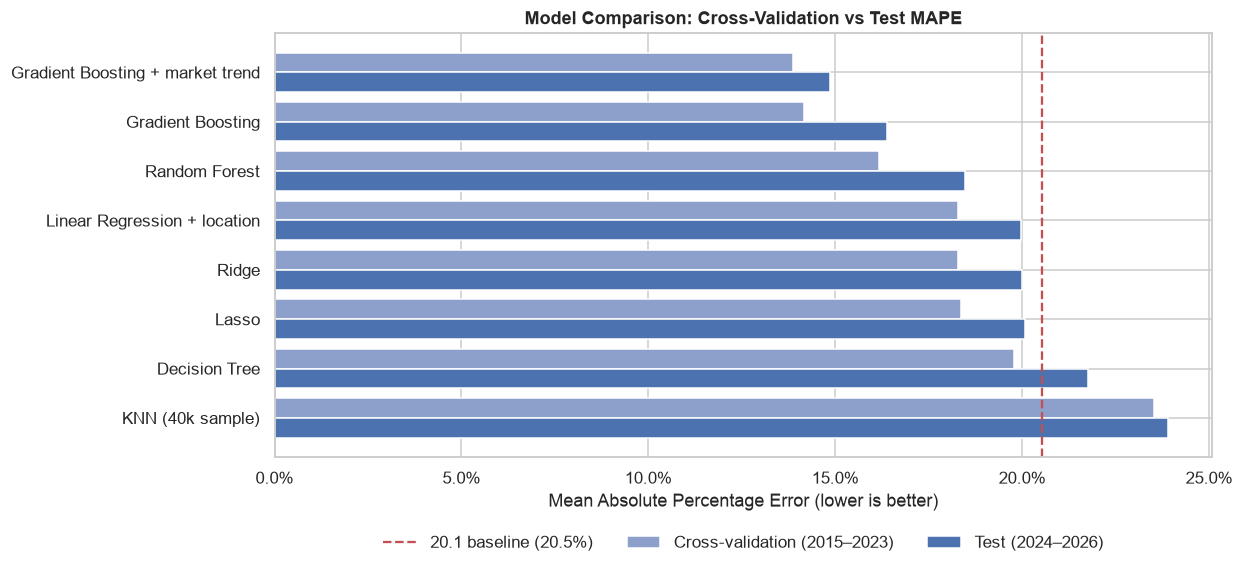

In [16]:
comparison = (pd.concat([pd.DataFrame(results), pd.DataFrame(model_rows)])
                .set_index("model").sort_values("MAPE (%)"))
display(comparison.drop(columns="best params").round(2))

plot_df = comparison.dropna(subset=["CV MAPE (%)"]).sort_values("MAPE (%)")
fig, ax = plt.subplots(figsize=(11, 5))
y_pos = np.arange(len(plot_df))
ax.barh(y_pos - 0.2, plot_df["CV MAPE (%)"], height=0.4, label="Cross-validation (2015–2023)", color="#8DA0CB")
ax.barh(y_pos + 0.2, plot_df["MAPE (%)"], height=0.4, label="Test (2024–2026)", color="#4C72B0")
baseline_mape = comparison.loc["Baseline: Linear Regression (20.1)", "MAPE (%)"]
ax.axvline(baseline_mape, color="#C44E52", linestyle="--", label=f"20.1 baseline ({baseline_mape:.1f}%)")
ax.set_yticks(y_pos, plot_df.index)
ax.invert_yaxis()
ax.set_xlabel("Mean Absolute Percentage Error (lower is better)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Model Comparison: Cross-Validation vs Test MAPE")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
fig.savefig(f"{IMAGE_DIR}/13_model_comparison.png", bbox_inches="tight", dpi=130)
plt.show()

### Key Findings

- **Best-performing model:** Gradient Boosting with the market-trend adjustment achieved a test MAPE of 14.86%, compared with 20.52% for the baseline Linear Regression model. This represents approximately 28% lower prediction error.
- **Tree-based ensemble models performed best:** Gradient Boosting and Random Forest captured non-linear relationships and interactions between features. For example, the impact of building age on property prices can vary between central and outer areas, which simpler linear models may not fully capture.
- **Regularisation had limited impact:** Ridge Regression achieved the same MAPE as Linear Regression with detailed location features (19.98%). With approximately 141,000 training records, overfitting does not appear to be a major issue for the linear models.
- **Location features provided a modest improvement to linear models:** Adding detailed location information reduced MAPE from 20.52% to 19.98%. The improvement was more noticeable when non-linear models used these features.
- **Decision Tree performed worse than the baseline:** It achieved a MAPE of 21.77%, suggesting that a single decision tree was less reliable than the baseline model.
- **KNN had the highest prediction error:** It achieved a MAPE of 23.89%. This may be due to distances becoming less meaningful with a large number of one-hot encoded features, along with the fact that KNN was trained on a smaller sample.
- **Test error was higher than cross-validation error across all models:** This reflects the challenge of predicting prices in a later period when the property market continued to change.
- **Further tuning may help:** The best Random Forest and Gradient Boosting configurations reached the boundaries of the parameter search grid. Expanding the search range could potentially improve their performance further.

## 8. Best Model: Overfitting Check and Save

In [17]:
best_name = "Gradient Boosting + market trend"
fit_check = pd.DataFrame([
    evaluate("Train (2015-2023)", y_train, add_trend(detrended_gb.predict(X_train), X_train)),
    evaluate("Test (2024-2026)", y_test, add_trend(detrended_gb.predict(X_test), X_test))]).set_index("model")
display(fit_check.round(2))

# Save the pipeline AND the trend: both are needed to make a prediction
joblib.dump({"pipeline": detrended_gb, "time_slope": time_slope}, f"{MODEL_DIR}/best_model.joblib")
comparison.drop(columns="best params").to_csv("../data/processed/model_comparison.csv")
print("Saved best model and comparison table")

,MAPE (%),Median APE (%),Within ±10% (%),MAE (¥M),R² (log price)
model,,,,,
Train (2015-2023),11.78,8.66,55.97,4.02,0.94
Test (2024-2026),14.86,11.08,45.69,7.13,0.91


Saved best model and comparison table


The best-performing model achieved a training MAPE of 11.78% and a test MAPE of 14.86%, with a cross-validation MAPE of 13.86% falling between the two. This indicates a moderate level of overfitting, but the overall test performance remains a significant improvement over the baseline.

In comparison, the Module 20.1 Linear Regression baseline showed signs of underfitting, with a training MAPE of 18.8% and a test MAPE of 20.5%.

The final model has been saved along with the market-trend value, as both are required to generate predictions correctly.

## 9. Summary

I trained and tuned seven machine learning models using time-series cross-validation and GridSearchCV. I also introduced a market-trend adjustment to improve the performance of the best tree-based model.

The final model, **Gradient Boosting with the market-trend adjustment**, achieved a test MAPE of **14.86%**, a median absolute percentage error of **11.1%**, and placed **45.7%** of predictions within ±10% of the actual price. It also achieved an R² of **0.91**, compared with a test MAPE of 20.52% for the Module 20.1 baseline.

One of the key findings was that tree-based models need to account for market trends separately when property prices continue to rise beyond the training period.

Notebook 3 explores how the selected model generates predictions and how it can be applied in practice.